Attempting to load data from: ../data/vote_log.csv
Successfully loaded 1 records.

First 5 records:
                         Timestamp  ElectionID  CandidateID   VoterHash
0 2025-10-22 12:54:57.538897+00:00           1            1  kishore123

Total Votes Logged: 1

Votes per Candidate ID:
CandidateID
1    1
Name: count, dtype: int64


C:\Users\reddy\AppData\Local\Temp\ipykernel_28676\3907511766.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='CandidateID', data=df, palette='viridis', order=votes_per_candidate.index)


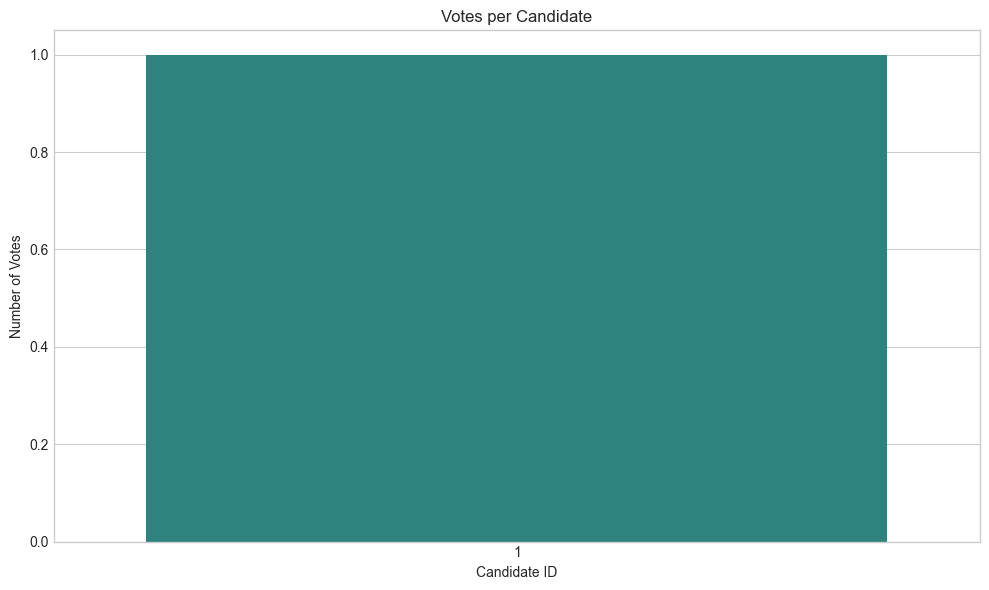

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Configuration ---
# Path relative to the 'notebooks' folder
log_file = '../data/vote_log.csv' 

# --- Load Data ---
print(f"Attempting to load data from: {log_file}")
if not os.path.exists(log_file):
    print(f"ERROR: Log file not found at {log_file}")
    # Create an empty DataFrame if file doesn't exist
    df = pd.DataFrame(columns=['Timestamp', 'ElectionID', 'CandidateID', 'VoterHash'])
else:
    try:
        df = pd.read_csv(log_file)
        # Convert Timestamp column to datetime objects
        df['Timestamp'] = pd.to_datetime(df['Timestamp'])
        print(f"Successfully loaded {len(df)} records.")
        print("\nFirst 5 records:")
        print(df.head())
    except Exception as e:
        print(f"ERROR loading or processing CSV: {e}")
        df = pd.DataFrame(columns=['Timestamp', 'ElectionID', 'CandidateID', 'VoterHash']) # Empty fallback

# --- Basic Analysis ---
if not df.empty:
    total_votes = len(df)
    print(f"\nTotal Votes Logged: {total_votes}")

    # Count votes per candidate (assuming only one election ID for now)
    votes_per_candidate = df['CandidateID'].value_counts()
    print("\nVotes per Candidate ID:")
    print(votes_per_candidate)

    # --- Visualization ---
    plt.style.use('seaborn-v0_8-whitegrid') # Use a nice style

    # Bar chart for votes per candidate
    plt.figure(figsize=(10, 6)) 
    sns.countplot(x='CandidateID', data=df, palette='viridis', order=votes_per_candidate.index)
    plt.title('Votes per Candidate')
    plt.xlabel('Candidate ID')
    plt.ylabel('Number of Votes')
    plt.xticks(rotation=0) 
    plt.tight_layout() 
    plt.show()

    # Optional: Plot votes over time (if you have enough data)
    if total_votes > 1:
        plt.figure(figsize=(12, 6))
        # Resample votes per hour 
        votes_over_time = df.set_index('Timestamp').resample('H').size() 
        votes_over_time.plot(kind='line', marker='o')
        plt.title('Voting Activity Over Time (Hourly)')
        plt.xlabel('Time')
        plt.ylabel('Number of Votes per Hour')
        plt.tight_layout()
        plt.show()
else:
    print("\nNo data loaded, skipping analysis and visualization.")